# 09 · DeBERTa-v3 con ajuste fino

Los embeddings genéricos de spaCy y Sentence-BERT no superaron, por sí solos, a predecir la media: miden **de qué
trata** un texto, no **qué tan bueno es**. La pregunta ahora es qué pasa si dejamos que un transformer aprenda
directamente la tarea. Con ajuste fino (*fine-tuning*), el modelo parte de lo que ya sabe del inglés y adapta sus
representaciones a lo que distingue un buen resumen, entrenando para predecir `content` y `wording`.

| Elemento | Decisión |
|---|---|
| Modelo | `microsoft/deberta-v3-base` (~184 M de parámetros) |
| Entrada | `prompt_question [SEP] resumen`, hasta 512 tokens |
| Salida | Mean pooling + capa lineal con 2 salidas (`content`, `wording`), pérdida MSE |
| Validación | `LeaveOneGroupOut` por `prompt_id`, los mismos 4 folds que 07 y 08 |
| Hiperparámetros | Fijados **antes** de ver resultados; sin early stopping |

**Por qué sin early stopping:** elegir la época mirando el error del prompt de validación sería usar ese prompt
para tomar decisiones del modelo (fuga de información). Se entrena un número fijo de épocas, igual que en 08 se
fijaron los parámetros de LightGBM de antemano.

**Dónde se ejecuta:** en Google Colab con GPU. El notebook detecta si está en Colab (usa una carpeta de Google
Drive) o en el repositorio local (usa `data/` y `outputs/`). Si la sesión se corta, al volver a ejecutarlo se
saltan los folds que ya terminaron.

## 1. Entorno, rutas y configuración

In [ ]:
import gc
import json
import os
import random
import sys
import time
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB: bool = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # El tokenizador de DeBERTa-v3 usa SentencePiece.
    get_ipython().run_line_magic("pip", "install -q sentencepiece protobuf")
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/proyecto2_DS_deberta")
    INPUT_DIR = BASE_DIR / "data"
    OUTPUT_DIR = BASE_DIR / "outputs"
    PROCESSED_DIR = TABLES_DIR = FIGURES_DIR = OUTPUT_DIR
    OOF_08_PATH = INPUT_DIR / "08_oof_predictions.csv"
else:
    PROJECT_ROOT = next(
        (path for path in [Path.cwd(), *Path.cwd().parents]
         if (path / "src").is_dir() and (path / "notebooks").is_dir()),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError("No se encontró la raíz del proyecto.")
    INPUT_DIR = PROJECT_ROOT / "data" / "interim"
    PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
    TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
    FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
    OOF_08_PATH = PROCESSED_DIR / "08_oof_predictions.csv"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut
from torch import nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModel, AutoTokenizer, DataCollatorWithPadding, get_linear_schedule_with_warmup

print("Colab:", IN_COLAB, "| entrada:", INPUT_DIR)

Mounted at /content/drive
Colab: True | entrada: /content/drive/MyDrive/proyecto2_DS_deberta/data


**Sintaxis:**

* `try: import google.colab ... except ImportError:` es la forma estándar de saber si el código corre en Colab:
  ese módulo solo existe ahí.
* `get_ipython().run_line_magic("pip", "...")` es lo mismo que escribir `%pip install ...` en una celda, pero
  dentro de un `if`, para que en local no intente instalar nada.
* `drive.mount(...)` conecta Google Drive como si fuera una carpeta más. Así los resultados sobreviven aunque
  Colab cierre la sesión (lo que se guarda en `/content` se borra).

In [ ]:
# ---- Prueba corta: True para comprobar que todo funciona antes de la corrida completa ----
SMOKE_TEST: bool = False

CONFIG: dict = dict(
    model_name="microsoft/deberta-v3-base",
    max_len=512,
    epochs=3,
    batch_size=8,
    lr_encoder=2e-5,      # tasa de aprendizaje de DeBERTa (pesos ya preentrenados: pasos pequeños)
    lr_head=1e-3,         # tasa de la capa nueva de regresión (empieza desde cero: pasos más grandes)
    weight_decay=0.01,
    warmup_ratio=0.10,
    max_grad_norm=1.0,
    seed=42,
)
if SMOKE_TEST:
    CONFIG.update(epochs=1, smoke_rows=400, smoke_folds=1)

TARGETS: list[str] = ["content", "wording"]
MODEL_LABEL: str = "DeBERTa-v3-base (fine-tuning)"

# En la prueba corta las salidas van a una subcarpeta para no mezclarse con la corrida real.
RUN_DIR: Path = (PROCESSED_DIR / "09_smoke_test") if SMOKE_TEST else PROCESSED_DIR
FOLDS_DIR: Path = RUN_DIR / "09_deberta_folds"
OUT_TABLES: Path = (RUN_DIR if SMOKE_TEST else TABLES_DIR)
OUT_FIGURES: Path = (RUN_DIR if SMOKE_TEST else FIGURES_DIR)
for directory in [FOLDS_DIR, OUT_TABLES, OUT_FIGURES]:
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP: bool = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"| memoria: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("Sin GPU: el entrenamiento completo sería demasiado lento. En Colab: Entorno de ejecución → "
          "Cambiar tipo de entorno de ejecución → GPU T4.")
print(json.dumps(CONFIG, indent=1))


def set_seed(seed: int) -> None:
    # Fija todas las fuentes de azar para que dos ejecuciones den resultados parecidos.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

GPU: Tesla T4 | memoria: 15.6 GB
{
 "model_name": "microsoft/deberta-v3-base",
 "max_len": 512,
 "epochs": 3,
 "batch_size": 8,
 "lr_encoder": 2e-05,
 "lr_head": 0.001,
 "weight_decay": 0.01,
 "warmup_ratio": 0.1,
 "max_grad_norm": 1.0,
 "seed": 42
}


* `CONFIG.update(...)` cambia solo algunas llaves del diccionario y conserva las demás.
* **Dos tasas de aprendizaje:** DeBERTa ya sabe mucho de inglés, así que sus pesos se mueven poco (`2e-5`); la capa
  de regresión es nueva y aleatoria, así que se le permite aprender más rápido (`1e-3`).
* `USE_AMP` activa la **precisión mixta** (fp16) solo con GPU: los cálculos se hacen con números de 16 bits donde es
  seguro, lo que ahorra memoria y casi duplica la velocidad en una T4.

## 2. Datos

Se usan las mismas copias limpias que en todos los notebooks anteriores. A cada resumen se le agrega la pregunta
de su prompt (`prompt_question`), que le dice al modelo qué se pedía resumir.

In [ ]:
summaries: pd.DataFrame = pd.read_csv(INPUT_DIR / "summaries_train_clean.csv")
prompts: pd.DataFrame = pd.read_csv(INPUT_DIR / "prompts_train_clean.csv")
data: pd.DataFrame = summaries.merge(prompts[["prompt_id", "prompt_question", "prompt_title"]],
                                     on="prompt_id", how="left", validate="many_to_one", sort=False)

assert len(data) == 7165 and data["student_id"].is_unique
assert data["prompt_id"].nunique() == 4
assert data[["text", "prompt_question", *TARGETS]].notna().all().all()
assert data["student_id"].tolist() == summaries["student_id"].tolist()   # mismo orden que en 08

if SMOKE_TEST:
    data = (data.groupby("prompt_id").sample(n=CONFIG["smoke_rows"] // 4, random_state=CONFIG["seed"])
                .reset_index(drop=True))

y: np.ndarray = data[TARGETS].to_numpy(dtype=np.float32)
groups: np.ndarray = data["prompt_id"].to_numpy()
print("Filas:", len(data), "| prompts:", sorted(data["prompt_id"].unique()))
display(data[["student_id", "prompt_title", "prompt_question", "text", *TARGETS]].head(3))

Filas: 7165 | prompts: ['39c16e', '3b9047', '814d6b', 'ebad26']


,student_id,prompt_title,prompt_question,text,content,wording
0,000e8c3c7ddb,The Third Wave,Summarize how the Third Wave developed over su...,The third wave was an experimentto see how peo...,0.205683,0.380538
1,0020ae56ffbf,Excerpt from The Jungle,Summarize the various ways the factory would u...,They would rub it up with soda to make the sme...,-0.548304,0.506755
2,004e978e639e,Egyptian Social Structure,"In complete sentences, summarize the structure...","In Egypt, there were many occupations and soci...",3.128928,4.231226


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"])

# Largo de cada entrada en tokens de DeBERTa, sin recortar, para saber cuántas exceden max_len
lengths: np.ndarray = np.array([
    len(ids) for ids in tokenizer(data["prompt_question"].tolist(), data["text"].tolist())["input_ids"]
])
print(f"Tokens por entrada: mediana={np.median(lengths):.0f}, p95={np.percentile(lengths, 95):.0f}, "
      f"máximo={lengths.max()}")
print(f"Entradas que exceden {CONFIG['max_len']} tokens: {(lengths > CONFIG['max_len']).mean():.2%}")

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Tokens por entrada: mediana=92, p95=240, máximo=854
Entradas que exceden 512 tokens: 0.17%


* El tokenizador de DeBERTa parte las palabras en **subpalabras** (por ejemplo, `summarizing` → `▁summar`, `izing`),
  así que el número de tokens es mayor que el número de palabras de `tokenize_text`.
* Si casi ninguna entrada pasa de 512 tokens, recortar en 512 no pierde información relevante.

## 3. Dataset y modelo

```
prompt_question [SEP] resumen  →  DeBERTa-v3  →  un vector por token  →  promedio (mean pooling)  →  Linear  →  [content, wording]
```

* **Mean pooling:** DeBERTa devuelve un vector por token; se promedian (ignorando el relleno) para tener un solo
  vector por resumen.
* La capa lineal final convierte ese vector en las dos puntuaciones.

In [ ]:
class SummaryDataset(Dataset):
    # Entrega cada resumen ya tokenizado junto con sus dos puntuaciones.

    def __init__(self, frame: pd.DataFrame, targets: np.ndarray | None = None):
        self.encodings = tokenizer(frame["prompt_question"].tolist(), frame["text"].tolist(),
                                   truncation="only_second", max_length=CONFIG["max_len"])
        self.targets = targets

    def __len__(self) -> int:
        return len(self.encodings["input_ids"])

    def __getitem__(self, index: int) -> dict:
        item = {key: values[index] for key, values in self.encodings.items()}
        if self.targets is not None:
            item["labels"] = self.targets[index].tolist()
        return item


class MeanPoolingRegressor(nn.Module):
    # DeBERTa + promedio de los vectores de los tokens + capa lineal con 2 salidas.

    def __init__(self, model_name: str, n_outputs: int = 2):
        super().__init__()
        # .float(): las versiones recientes de transformers cargan los pesos en el tipo guardado en el archivo
        # (fp16 en deberta-v3-base). Para entrenar con GradScaler los pesos deben estar en fp32.
        self.encoder = AutoModel.from_pretrained(model_name).float()
        self.head = nn.Linear(self.encoder.config.hidden_size, n_outputs)

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask,
                              token_type_ids=token_type_ids).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        return self.head(pooled)


collator = DataCollatorWithPadding(tokenizer)

**Sintaxis:**

* `class SummaryDataset(Dataset)`: PyTorch pide dos métodos, `__len__` (cuántos ejemplos hay) y `__getitem__`
  (devolver el ejemplo número `index`). El `DataLoader` los usa para armar lotes.
* `truncation="only_second"` recorta solo el **resumen** (el segundo texto) si la entrada es muy larga; la pregunta
  del prompt siempre queda completa.
* `DataCollatorWithPadding` rellena con ceros los resúmenes de cada lote hasta el más largo **de ese lote**, no hasta
  512. Eso ahorra mucho tiempo porque la mayoría de los resúmenes son cortos.
* `attention_mask.unsqueeze(-1)` agrega una dimensión al final para poder multiplicar la máscara `(lote, tokens)`
  por los vectores `(lote, tokens, 768)`. Los tokens de relleno tienen máscara 0 y no cuentan en el promedio.
* `.clamp(min=1e-9)` evita dividir entre cero.

## 4. Entrenamiento con Leave-One-Prompt-Out

Para cada fold se entrena un modelo **nuevo** con 3 prompts y se predice el cuarto. Al terminar cada fold, sus
predicciones se guardan en un archivo propio; si la sesión se corta, al volver a ejecutar esta celda los folds
terminados se cargan del disco en vez de entrenarse otra vez.

In [ ]:
def make_loader(frame: pd.DataFrame, targets: np.ndarray | None, shuffle: bool) -> DataLoader:
    return DataLoader(SummaryDataset(frame, targets), batch_size=CONFIG["batch_size"],
                      shuffle=shuffle, collate_fn=collator)


def to_device(batch: dict) -> dict:
    return {key: value.to(DEVICE) for key, value in batch.items()}


def train_one_fold(train_frame: pd.DataFrame, train_targets: np.ndarray) -> tuple[nn.Module, list[float]]:
    set_seed(CONFIG["seed"])
    model = MeanPoolingRegressor(CONFIG["model_name"], n_outputs=len(TARGETS)).to(DEVICE)
    loader = make_loader(train_frame, train_targets, shuffle=True)

    optimizer = torch.optim.AdamW([
        {"params": model.encoder.parameters(), "lr": CONFIG["lr_encoder"]},
        {"params": model.head.parameters(), "lr": CONFIG["lr_head"]},
    ], weight_decay=CONFIG["weight_decay"])
    total_steps = len(loader) * CONFIG["epochs"]
    scheduler = get_linear_schedule_with_warmup(optimizer, int(CONFIG["warmup_ratio"] * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loss_fn = nn.MSELoss()

    epoch_losses: list[float] = []
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()
        running, start = 0.0, time.perf_counter()
        for step, batch in enumerate(loader, start=1):
            batch = to_device(batch)
            labels = batch.pop("labels")
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                predictions = model(**batch)
            loss = loss_fn(predictions.float(), labels.float())

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running += loss.item()
            if step % 100 == 0 or step == len(loader):
                print(f"  época {epoch} · paso {step}/{len(loader)} · MSE promedio {running / step:.4f}", flush=True)
        epoch_losses.append(running / len(loader))
        print(f"  época {epoch} terminada en {time.perf_counter() - start:.0f} s", flush=True)
    return model, epoch_losses


@torch.no_grad()
def predict(model: nn.Module, frame: pd.DataFrame) -> np.ndarray:
    model.eval()
    outputs = []
    for batch in make_loader(frame, None, shuffle=False):
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            outputs.append(model(**to_device(batch)).float().cpu().numpy())
    return np.vstack(outputs)

**Sintaxis:**

* `AdamW([{...}, {...}])`: cada diccionario es un **grupo de parámetros** con su propia tasa de aprendizaje.
* `get_linear_schedule_with_warmup` sube la tasa de aprendizaje desde 0 durante el primer 10% de pasos (warmup) y
  luego la baja linealmente hasta 0. Evita pasos bruscos al inicio, cuando la capa nueva todavía es aleatoria.
* `torch.amp.autocast(...)` + `GradScaler`: precisión mixta. El `scaler` multiplica la pérdida antes de
  `backward()` para que los gradientes pequeños no se vuelvan cero en 16 bits, y la divide de nuevo antes de
  actualizar los pesos (`unscale_`).
* `clip_grad_norm_` limita el tamaño total del gradiente a 1.0 para que un lote raro no desestabilice el modelo.
* `@torch.no_grad()` desactiva el cálculo de gradientes al predecir: más rápido y con menos memoria.
* `model.train()` / `model.eval()` activan o desactivan el *dropout*, que solo debe usarse al entrenar.

In [ ]:
logo = LeaveOneGroupOut()
folds = list(logo.split(data, y, groups))
if SMOKE_TEST:
    folds = folds[:CONFIG["smoke_folds"]]

fold_log_path: Path = OUT_TABLES / "09_deberta_fold_log.csv"
fold_log: list[dict] = pd.read_csv(fold_log_path).to_dict("records") if fold_log_path.exists() else []

for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
    prompt_id = groups[valid_idx][0]
    fold_path = FOLDS_DIR / f"09_deberta_fold_{prompt_id}.csv"
    if fold_path.exists():
        print(f"Fold {fold} ({prompt_id}): ya existe, se carga de {fold_path.name}")
        continue

    print(f"Fold {fold} ({prompt_id}, {data.loc[valid_idx[0], 'prompt_title']}): "
          f"entrenamiento={len(train_idx)}, validación={len(valid_idx)}", flush=True)
    start = time.perf_counter()
    model, epoch_losses = train_one_fold(data.iloc[train_idx], y[train_idx])
    prediction = predict(model, data.iloc[valid_idx])
    seconds = time.perf_counter() - start

    fold_frame = data.iloc[valid_idx][["student_id", "prompt_id"]].copy()
    fold_frame["pred_content"], fold_frame["pred_wording"] = prediction[:, 0], prediction[:, 1]
    fold_frame.to_csv(fold_path, index=False)

    fold_rmse = [root_mean_squared_error(y[valid_idx, j], prediction[:, j]) for j in range(len(TARGETS))]
    fold_log.append({"fold": fold, "prompt_id": prompt_id, "segundos": seconds,
                     "mse_entrenamiento_ultima_epoca": epoch_losses[-1],
                     "rmse_content": fold_rmse[0], "rmse_wording": fold_rmse[1],
                     "mcrmse": float(np.mean(fold_rmse))})
    pd.DataFrame(fold_log).to_csv(fold_log_path, index=False)
    print(f"Fold {fold} listo en {seconds / 60:.1f} min · MCRMSE {np.mean(fold_rmse):.4f}", flush=True)

    del model
    gc.collect()
    torch.cuda.empty_cache()

display(pd.DataFrame(fold_log).round(4))

Fold 1 (39c16e, On Tragedy): entrenamiento=5108, validación=2057


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

  época 1 · paso 100/758 · MSE promedio 0.8054
  época 1 · paso 200/758 · MSE promedio 0.5883
  época 1 · paso 300/758 · MSE promedio 0.5127
  época 1 · paso 400/758 · MSE promedio 0.4696
  época 1 · paso 500/758 · MSE promedio 0.4369
  época 1 · paso 600/758 · MSE promedio 0.4123
  época 1 · paso 700/758 · MSE promedio 0.3897
  época 1 · paso 758/758 · MSE promedio 0.3792
  época 1 terminada en 180 s
  época 2 · paso 100/758 · MSE promedio 0.2208
  época 2 · paso 200/758 · MSE promedio 0.2226
  época 2 · paso 300/758 · MSE promedio 0.2252
  época 2 · paso 400/758 · MSE promedio 0.2280
  época 2 · paso 500/758 · MSE promedio 0.2255
  época 2 · paso 600/758 · MSE promedio 0.2212
  época 2 · paso 700/758 · MSE promedio 0.2204
  época 2 · paso 758/758 · MSE promedio 0.2189
  época 2 terminada en 182 s
  época 3 · paso 100/758 · MSE promedio 0.1562
  época 3 · paso 200/758 · MSE promedio 0.1546
  época 3 · paso 300/758 · MSE promedio 0.1607
  época 3 · paso 400/758 · MSE promedio 0.1613
  

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_4090/3829900288.py:41: 

  época 1 · paso 100/647 · MSE promedio 0.8965
  época 1 · paso 200/647 · MSE promedio 0.6443
  época 1 · paso 300/647 · MSE promedio 0.5539
  época 1 · paso 400/647 · MSE promedio 0.5064
  época 1 · paso 500/647 · MSE promedio 0.4772
  época 1 · paso 600/647 · MSE promedio 0.4467
  época 1 · paso 647/647 · MSE promedio 0.4345
  época 1 terminada en 150 s
  época 2 · paso 100/647 · MSE promedio 0.2731
  época 2 · paso 200/647 · MSE promedio 0.2737
  época 2 · paso 300/647 · MSE promedio 0.2620
  época 2 · paso 400/647 · MSE promedio 0.2560
  época 2 · paso 500/647 · MSE promedio 0.2517
  época 2 · paso 600/647 · MSE promedio 0.2475
  época 2 · paso 647/647 · MSE promedio 0.2435
  época 2 terminada en 150 s
  época 3 · paso 100/647 · MSE promedio 0.1870
  época 3 · paso 200/647 · MSE promedio 0.1840
  época 3 · paso 300/647 · MSE promedio 0.1821
  época 3 · paso 400/647 · MSE promedio 0.1750
  época 3 · paso 500/647 · MSE promedio 0.1718
  época 3 · paso 600/647 · MSE promedio 0.1677
  

,fold,prompt_id,segundos,mse_entrenamiento_ultima_epoca,rmse_content,rmse_wording,mcrmse
0,1,39c16e,502.2913,0.1686,0.4319,0.8188,0.6253
1,2,3b9047,446.1142,0.1514,0.4887,0.7789,0.6338
2,3,814d6b,552.1813,0.1572,0.5236,0.7307,0.6272
3,4,ebad26,467.0110,0.1664,0.4253,0.6062,0.5157


* Cada fold guarda `09_deberta_fold_<prompt_id>.csv` apenas termina. Si Colab se desconecta, basta con volver a
  ejecutar todas las celdas: `if fold_path.exists(): continue` salta lo ya hecho.
* `del model`, `gc.collect()` y `torch.cuda.empty_cache()` liberan la memoria de la GPU antes del siguiente fold.
* El MSE de entrenamiento se registra solo para revisar que el modelo aprende; **no** se usa para elegir nada.
* El aviso `Detected call of lr_scheduler.step() before optimizer.step()` es inofensivo. Con precisión mixta,
  `scaler.step(optimizer)` **se salta** la actualización si encuentra gradientes infinitos, algo normal en los primeros
  pasos mientras el `GradScaler` calibra su escala. En ese paso el scheduler sí avanza y PyTorch lo detecta como si se
  hubiera llamado antes que el optimizador. Solo se pierde un valor del warmup, de más de 1,900 pasos por fold.

## 5. Resultados out-of-fold

Se juntan las predicciones de los folds. Cada resumen fue predicho por un modelo que nunca vio su prompt, igual que
en 07 y 08, así que las métricas son directamente comparables.

In [ ]:
def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    # Misma fórmula que src/evaluation.regression_metrics (aquí se copia para no depender del repositorio en Colab).
    metrics: dict[str, float] = {}
    rmse_values = []
    for j, target in enumerate(TARGETS):
        rmse = root_mean_squared_error(y_true[:, j], y_pred[:, j])
        rmse_values.append(rmse)
        metrics[f"rmse_{target}"] = rmse
        metrics[f"mae_{target}"] = mean_absolute_error(y_true[:, j], y_pred[:, j])
        metrics[f"r2_{target}"] = r2_score(y_true[:, j], y_pred[:, j])
    metrics["mcrmse"] = float(np.mean(rmse_values))
    return metrics


fold_files = sorted(FOLDS_DIR.glob("09_deberta_fold_*.csv"))
predicted = pd.concat([pd.read_csv(path) for path in fold_files], ignore_index=True)
assert predicted["student_id"].is_unique
if not SMOKE_TEST:
    assert len(fold_files) == 4 and len(predicted) == len(data), "Faltan folds: vuelva a ejecutar la sección 4."

oof = (data[["student_id", "prompt_id", "prompt_title", *TARGETS]]
       .merge(predicted.drop(columns="prompt_id"), on="student_id", how="inner", validate="one_to_one"))
oof["modelo"] = MODEL_LABEL
for target in TARGETS:
    oof[f"error_abs_{target}"] = (oof[target] - oof[f"pred_{target}"]).abs()

y_oof = oof[TARGETS].to_numpy()
p_oof = oof[["pred_content", "pred_wording"]].to_numpy()
results = pd.DataFrame([{"modelo": MODEL_LABEL, "filas": len(oof), **regression_metrics(y_oof, p_oof)}])
by_prompt = pd.DataFrame([
    {"prompt_id": prompt_id, "prompt_title": g["prompt_title"].iloc[0], "filas": len(g),
     **regression_metrics(g[TARGETS].to_numpy(), g[["pred_content", "pred_wording"]].to_numpy())}
    for prompt_id, g in oof.groupby("prompt_id")
])
display(results.round(4))
display(by_prompt.round(4))

columns_08 = ["student_id", "prompt_id", *TARGETS, "modelo", "pred_content", "error_abs_content",
              "pred_wording", "error_abs_wording"]
oof[columns_08].to_csv(RUN_DIR / "09_deberta_oof_predictions.csv", index=False)
results.to_csv(OUT_TABLES / "09_deberta_results.csv", index=False)
by_prompt.to_csv(OUT_TABLES / "09_deberta_by_prompt.csv", index=False)

,modelo,filas,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,DeBERTa-v3-base (fine-tuning),7165,0.4616,0.3518,0.8043,0.7397,0.5855,0.4902,0.6007


,prompt_id,prompt_title,filas,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,39c16e,On Tragedy,2057,0.4319,0.3383,0.8016,0.8188,0.6966,0.3982,0.6253
1,3b9047,Egyptian Social Structure,2009,0.4887,0.3655,0.8047,0.7789,0.5833,0.3313,0.6338
2,814d6b,The Third Wave,1103,0.5236,0.3973,0.7829,0.7307,0.5584,0.5645,0.6272
3,ebad26,Excerpt from The Jungle,1996,0.4253,0.3267,0.8155,0.6062,0.4883,0.5752,0.5157


* `validate="one_to_one"` hace que `merge` falle si algún `student_id` aparece repetido: es una verificación gratis.
* `09_deberta_oof_predictions.csv` tiene **las mismas columnas** que `08_oof_predictions.csv` y
  `07_tfidf_oof_predictions.csv`, para poder compararlos directamente al final del proyecto.

## 6. Comparación con el notebook 08 y promedio fijo 50/50

Si `08_oof_predictions.csv` está disponible (en Colab, subirlo a la carpeta `data/` de Drive), se compara DeBERTa
con los modelos de 08 **en los mismos resúmenes**. También se prueba el promedio simple de DeBERTa y la fusión
mínima de 08. El peso 50/50 se fijó **antes** de ver los resultados: elegirlo mirando el error OOF sería ajustar
un parámetro con los datos de evaluación.

In [ ]:
REFERENCE_MODELS: list[str] = ["Solo largo + Ridge", "A. Features + LightGBM",
                               "Opción 1: Fusión mínima (A + cos_sim) + LightGBM"]
BLEND_BASE: str = "Opción 1: Fusión mínima (A + cos_sim) + LightGBM"

if OOF_08_PATH.exists():
    oof_08 = pd.read_csv(OOF_08_PATH)
    oof_08 = oof_08[oof_08["student_id"].isin(oof["student_id"])]
    rows = []
    for name in REFERENCE_MODELS:
        ref = oof[["student_id"]].merge(oof_08[oof_08["modelo"] == name], on="student_id", validate="one_to_one")
        rows.append({"modelo": name, **regression_metrics(ref[TARGETS].to_numpy(),
                                                          ref[["pred_content", "pred_wording"]].to_numpy())})
    rows.append({"modelo": MODEL_LABEL, **regression_metrics(y_oof, p_oof)})

    base = oof[["student_id"]].merge(oof_08[oof_08["modelo"] == BLEND_BASE], on="student_id", validate="one_to_one")
    blend = 0.5 * p_oof + 0.5 * base[["pred_content", "pred_wording"]].to_numpy()
    rows.append({"modelo": "Promedio 50/50: DeBERTa + fusión mínima", **regression_metrics(y_oof, blend)})

    comparison = pd.DataFrame(rows).sort_values("mcrmse").reset_index(drop=True)
    display(comparison.round(4))
    comparison.to_csv(OUT_TABLES / "09_deberta_comparison.csv", index=False)
else:
    print(f"No se encontró {OOF_08_PATH}; se omite la comparación con 08.")

,modelo,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,Promedio 50/50: DeBERTa + fusión mínima,0.4327,0.3317,0.8280,0.6243,0.4960,0.6368,0.5285
1,Opción 1: Fusión mínima (A + cos_sim) + LightGBM,0.4800,0.3711,0.7884,0.6713,0.5193,0.5801,0.5756
2,A. Features + LightGBM,0.4853,0.3747,0.7837,0.6771,0.5219,0.5729,0.5812
3,DeBERTa-v3-base (fine-tuning),0.4616,0.3518,0.8043,0.7397,0.5855,0.4902,0.6007
4,Solo largo + Ridge,0.5607,0.4233,0.7113,0.8624,0.6739,0.3070,0.7116


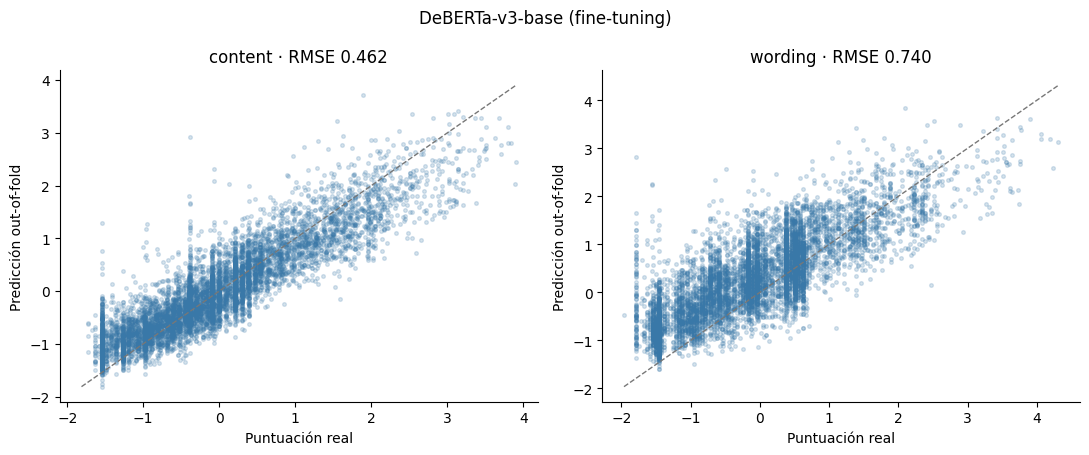

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=[11, 4.6])
for j, (ax, target) in enumerate(zip(axes, TARGETS)):
    ax.scatter(y_oof[:, j], p_oof[:, j], s=7, alpha=0.2, color="#3978a8")
    limits = [min(y_oof[:, j].min(), p_oof[:, j].min()), max(y_oof[:, j].max(), p_oof[:, j].max())]
    ax.plot(limits, limits, color="#777777", linestyle="--", linewidth=1)
    ax.set(title=f"{target} · RMSE {root_mean_squared_error(y_oof[:, j], p_oof[:, j]):.3f}",
           xlabel="Puntuación real", ylabel="Predicción out-of-fold")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(MODEL_LABEL)
fig.tight_layout()
fig.savefig(OUT_FIGURES / "09_deberta_pred_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Conclusiones

Corrida completa en Colab (GPU T4) con la configuración de la sección 1 sin cambios. Todas las cifras son MCRMSE con
Leave-One-Prompt-Out, es decir, con un prompt que el modelo nunca vio.

| Modelo | RMSE content | RMSE wording | MCRMSE |
|---|---|---|---|
| Solo largo + Ridge (08) | 0.561 | 0.862 | 0.712 |
| A. Features + LightGBM (08) | 0.485 | 0.677 | 0.581 |
| Fusión mínima (A + cos_sim) + LightGBM (08) | 0.480 | 0.671 | 0.576 |
| DeBERTa-v3-base (fine-tuning) | **0.462** | 0.740 | 0.601 |
| **Promedio 50/50: DeBERTa + fusión mínima** | **0.433** | **0.624** | **0.529** |

1. **DeBERTa solo no supera a la fusión mínima** (0.601 contra 0.576). Queda por encima de "Solo largo" (0.712) y de
   todos los baselines léxicos, pero por detrás de las features manuales con LightGBM.
2. **Mejora en `content` y empeora en `wording`.** En `content` es el mejor modelo individual (RMSE 0.462, R² 0.80,
   contra 0.480 y R² 0.79 de la fusión mínima). En `wording` cae a RMSE 0.740 (R² 0.49), peor que la fusión (0.671,
   R² 0.58). La gráfica lo muestra: en `wording` las predicciones se comprimen hacia el centro, los resúmenes con
   puntuación baja (alrededor de −1.5) se sobreestiman y los altos (más de 2) se subestiman.
   Una explicación posible, no comprobada aquí: la entrada de DeBERTa lleva la pregunta del prompt, pero no el texto
   fuente, así que el modelo no puede ver cuánto copia el resumen del original. Las features de 08 sí lo miden
   (`palabras_prompt_overlap`). Por eso el texto fuente es el primer candidato para mejorar la entrada del transformer.
3. **El promedio 50/50 es el mejor resultado del proyecto: MCRMSE 0.529**, 0.047 menos que la fusión mínima (−8 %)
   y 0.072 menos que DeBERTa. Mejora los dos objetivos (content 0.433, wording 0.624). El peso 50/50 se fijó antes de
   ver los resultados, así que no está ajustado al conjunto de validación. Que el promedio gane a los dos modelos por
   separado indica que capturan información distinta: el transformer, el significado del resumen; las features, el
   largo y la relación con el texto fuente.
4. **El resultado depende del prompt.** Por prompt, DeBERTa contra la fusión mínima:
   - *The Third Wave* (814d6b): 0.627 contra 0.672. Es el único prompt donde DeBERTa gana, y es el más difícil para
     todos los modelos de 08.
   - *Excerpt from The Jungle* (ebad26): 0.516 contra 0.512, prácticamente igual.
   - *Egyptian Social Structure* (3b9047): 0.634 contra 0.625, un poco peor.
   - *On Tragedy* (39c16e): 0.625 contra 0.522, claramente peor. Casi todo viene de `wording` (RMSE 0.819).
5. **Costo.** Entre 7.4 y 9.2 minutos por fold en una T4 (unos 33 minutos en total), contra segundos para LightGBM en
   CPU. El MSE de entrenamiento de la última época (0.15–0.17) queda muy por debajo del de validación, sobre todo en
   `wording`, así que el modelo aprende bien los prompts que ve y generaliza peor el estilo a un prompt nuevo.
   No se usó early stopping, para no elegir la época con el prompt de validación.

**En síntesis:** el transformer con ajuste fino es el mejor modelo para `content`, pero no para `wording`, donde
las features manuales siguen ganando. Ninguno de los dos domina al otro, y su promedio simple baja el MCRMSE de 0.576
a 0.529. El modelo final recomendado es esa combinación.

## Cierre

El transformer no ganó por sí solo, pero dejó dos preguntas abiertas. La primera es si su configuración era la
adecuada: el error de entrenamiento quedó muy por debajo del de validación, lo que sugiere que entrenar menos podría
generalizar mejor. La segunda es si su debilidad en `wording` se debe a que nunca ve el texto fuente. Las dos se
pueden poner a prueba ajustando el modelo.